# Experiment 08 — External Paper Reproduction

## E7 — Temporal Order Sensitivity

### 1. Mục tiêu

Tái thực nghiệm phép kiểm tra mức độ nhạy cảm với thứ tự thời gian được trình bày trong **Table 5** của bài báo *Are Transformers Effective for Time Series Forecasting?* (Zeng et al., AAAI 2023).

Đánh giá mức độ thay đổi hiệu năng dự báo của LTSF-Linear khi thứ tự các quan sát trong chuỗi đầu vào bị thay đổi.

### 2. Thiết kế thực nghiệm

**Dataset:** ETTh1 — 7 channels.

**Model:** LTSF-Linear.

**Input Sequence Length:** 96.

**Forecasting Horizons:** 96, 192, 336, 720.

**Random Seeds:** 7, 17, 27, 37, 47.

Sử dụng 20 checkpoint đã huấn luyện trong `02_linear_reproduction.ipynb`.

### 3. Input Transformations

Thực nghiệm gồm ba điều kiện:

- **Original:** Giữ nguyên thứ tự thời gian của dữ liệu đầu vào.
- **Shuffle:** Hoán vị ngẫu nhiên thứ tự các timestamp trong cửa sổ đầu vào.
- **Half-Exchange:** Hoán đổi nửa đầu và nửa sau của cửa sổ đầu vào.

Các phép biến đổi được áp dụng lên dữ liệu đầu vào Test, giữ nguyên nhãn dự báo và trọng số mô hình.

**Training bổ sung: 0 — Inference Only.**

### 4. Chỉ số đánh giá

- Mean Squared Error (MSE).
- Mean Absolute Error (MAE).
- Relative MSE Degradation (%).
- Mean ± Standard Deviation giữa các random seeds.

### 5. Quy trình thực hiện

1. Nạp 20 checkpoint LTSF-Linear đã huấn luyện.
2. Đánh giá dữ liệu Test với thứ tự gốc.
3. Tạo hai biến thể Shuffle và Half-Exchange.
4. Đánh giá lại mô hình trên dữ liệu đã biến đổi.
5. So sánh kết quả giữa ba điều kiện.
6. Tổng hợp bảng và trực quan hóa kết quả.

### 6. Kết quả đầu ra

- `temporal_order_metrics.csv` — Kết quả đánh giá theo horizon, seed và transformation.
- `temporal_order_summary.csv` — Bảng tổng hợp MSE, MAE và Degradation.
- Các biểu đồ so sánh hiệu năng giữa Original, Shuffle và Half-Exchange.

Kết quả được sử dụng để phân tích mức độ nhạy cảm với thứ tự thời gian của Linear và làm cơ sở cho thí nghiệm mở rộng trên DeepKoopFormer.

TEMPORAL ORDER: SETUP & LOAD LINEAR MODELS

In [1]:
from pathlib import Path
import hashlib
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# 1. Reproducibility
SEED = 7
EVAL_SEEDS = [7, 17, 27, 37, 47]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 2. Locate project root
PROJECT_ROOT = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (
            p / "datasets" / "ETTh1" / "ETTh1.csv"
        ).is_file()
    ),
    None
)

assert PROJECT_ROOT is not None, "Project root not found"

EXTERNAL_DIR = (
    PROJECT_ROOT / "experiments" / "08_external_paper"
)

RAW_DATA_PATH = (
    PROJECT_ROOT / "datasets" / "ETTh1" / "ETTh1.csv"
)

PREPARED_PATH = (
    EXTERNAL_DIR / "results"
    / "etth1_data" / "etth1_prepared.pt"
)

LINEAR_DIR = (
    EXTERNAL_DIR / "results" / "linear_reproduction"
)

MODEL_DIR = LINEAR_DIR / "models"

RESULTS_DIR = (
    EXTERNAL_DIR / "results" / "temporal_order_test"
)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

assert PREPARED_PATH.is_file()

# 3. Load prepared ETTh1 data
bundle = torch.load(
    PREPARED_PATH,
    map_location="cpu",
    weights_only=True
)

RAW_SHA256 = hashlib.sha256(
    RAW_DATA_PATH.read_bytes()
).hexdigest()

assert bundle["dataset"] == "ETTh1"
assert bundle["source_sha256"] == RAW_SHA256
assert bundle["normalization"] == "StandardScaler"

SEQ_LEN = int(bundle["seq_len"])
PRED_LENGTHS = list(bundle["pred_lengths"])
N_CHANNELS = int(bundle["channels"])

ETTH1_SPLITS = {
    split: bundle[split].float()
    for split in ["train", "val", "test"]
}

SCALER_MEAN = bundle["scaler_mean"]
SCALER_SCALE = bundle["scaler_scale"]

assert SEQ_LEN == 96
assert PRED_LENGTHS == [96, 192, 336, 720]
assert N_CHANNELS == 7
assert ETTH1_SPLITS["test"].shape == (2976, 7)

# 4. Restore exact Linear architecture
class LTSFLinear(nn.Module):

    def __init__(
        self, seq_len, pred_len,
        channels, individual=False
    ):
        super().__init__()

        self.seq_len = seq_len
        self.pred_len = pred_len
        self.channels = channels
        self.individual = individual

        if individual:
            self.Linear = nn.ModuleList([
                nn.Linear(seq_len, pred_len)
                for _ in range(channels)
            ])
        else:
            self.Linear = nn.Linear(seq_len, pred_len)

    def forward(self, x):

        assert x.ndim == 3
        assert x.shape[1:] == (
            self.seq_len, self.channels
        )

        if self.individual:
            return torch.stack(
                [
                    self.Linear[c](x[:, :, c])
                    for c in range(self.channels)
                ],
                dim=-1
            )

        return self.Linear(
            x.permute(0, 2, 1)
        ).permute(0, 2, 1)


# 5. Load all completed checkpoints
LINEAR_MODELS = {}
BASELINE_META = {}
rows = []

for horizon in PRED_LENGTHS:
    for seed in EVAL_SEEDS:

        checkpoint_path = MODEL_DIR / (
            f"linear_h{horizon}_seed{seed}.pt"
        )

        assert checkpoint_path.is_file(), (
            f"Missing checkpoint: {checkpoint_path.name}"
        )

        artifact = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

        config = artifact["config"]

        assert config["dataset"] == "ETTh1"
        assert config["model"] == "Linear"
        assert config["horizon"] == horizon
        assert config["seed"] == seed
        assert config["seq_len"] == SEQ_LEN
        assert config["channels"] == N_CHANNELS
        assert config["individual"] is False
        assert config["source_sha256"] == RAW_SHA256

        model = LTSFLinear(
            seq_len=SEQ_LEN,
            pred_len=horizon,
            channels=N_CHANNELS,
            individual=False
        )

        model.load_state_dict(
            artifact["model_state_dict"],
            strict=True
        )

        model = model.to(DEVICE)
        model.eval()

        # 6. Test forward pass
        dummy_x = (
            ETTH1_SPLITS["test"][:SEQ_LEN]
            .unsqueeze(0)
            .to(DEVICE)
        )

        with torch.inference_mode():
            prediction = model(dummy_x)

        assert prediction.shape == (
            1, horizon, N_CHANNELS
        )
        assert torch.isfinite(prediction).all()

        # Baseline metrics saved by previous notebook
        test_scores = artifact["scores"]["test"]

        assert np.isfinite(test_scores["MSE"])
        assert np.isfinite(test_scores["MAE"])

        key = (horizon, seed)

        LINEAR_MODELS[key] = model
        BASELINE_META[key] = test_scores

        rows.append({
            "Horizon": horizon,
            "Seed": seed,
            "Best_Epoch": artifact["best_epoch"],
            "Test_MSE_Saved": test_scores["MSE"],
            "Test_MAE_Saved": test_scores["MAE"],
            "Status": "PASSED"
        })

# 7. Verify 20 loaded models
MODEL_SUMMARY = pd.DataFrame(rows)

assert len(LINEAR_MODELS) == 20
assert len(MODEL_SUMMARY) == 20
assert (MODEL_SUMMARY["Status"] == "PASSED").all()

# 8. Summary
print("=== E7 — TEMPORAL ORDER TEST SETUP ===")

print("Project:", PROJECT_ROOT)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("\nDataset: ETTh1")
print("Sequence length:", SEQ_LEN)
print("Channels:", N_CHANNELS)
print("Forecast horizons:", PRED_LENGTHS)
print("Seeds:", EVAL_SEEDS)

print("\n=== LOADED LINEAR CHECKPOINTS ===")
display(MODEL_SUMMARY.round(6))

print("\nCheckpoints loaded:", len(LINEAR_MODELS), "/ 20")
print("All model weights restored successfully.")
print("All forward-pass checks passed.")

print("\nTraining required: NO")
print("Evaluation mode: INFERENCE ONLY")
print("Results:", RESULTS_DIR)

print("\nTEMPORAL ORDER SETUP PASSED!")


c:\Users\Win 11 New\Desktop\pa gk\.venv\lib\site-packages\torch\_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


=== E7 — TEMPORAL ORDER TEST SETUP ===
Project: c:\Users\Win 11 New\Desktop\pa gk
Device: cuda
GPU: Quadro T1000

Dataset: ETTh1
Sequence length: 96
Channels: 7
Forecast horizons: [96, 192, 336, 720]
Seeds: [7, 17, 27, 37, 47]

=== LOADED LINEAR CHECKPOINTS ===


,Horizon,Seed,Best_Epoch,Test_MSE_Saved,Test_MAE_Saved,Status
0,96,7,7,0.383510,0.395798,PASSED
1,96,17,6,0.382719,0.394416,PASSED
2,96,27,4,0.387071,0.401631,PASSED
3,96,37,7,0.382899,0.395318,PASSED
4,96,47,3,0.387588,0.400464,PASSED
5,192,7,5,0.434216,0.427840,PASSED
6,192,17,5,0.435056,0.428512,PASSED
7,192,27,3,0.441202,0.434652,PASSED
8,192,37,3,0.443759,0.437600,PASSED
9,192,47,1,0.451323,0.446407,PASSED



Checkpoints loaded: 20 / 20
All model weights restored successfully.
All forward-pass checks passed.

Training required: NO
Evaluation mode: INFERENCE ONLY
Results: c:\Users\Win 11 New\Desktop\pa gk\experiments\08_external_paper\results\temporal_order_test

TEMPORAL ORDER SETUP PASSED!


TEST WINDOWS & ORIGINAL BASELINE VALIDATION

In [2]:
from torch.utils.data import Dataset, DataLoader
import time

# 1. Sliding Window Dataset
class TemporalTestDataset(Dataset):

    def __init__(self, series, seq_len, pred_len):
        self.series = series
        self.seq_len = int(seq_len)
        self.pred_len = int(pred_len)

        assert series.ndim == 2
        assert series.shape[1] == N_CHANNELS
        assert len(series) >= seq_len + pred_len

    def __len__(self):
        return (
            len(self.series)
            - self.seq_len
            - self.pred_len
            + 1
        )

    def __getitem__(self, idx):
        if idx < 0 or idx >= len(self):
            raise IndexError(idx)

        x_end = idx + self.seq_len
        y_end = x_end + self.pred_len

        X = self.series[idx:x_end]
        Y = self.series[x_end:y_end]

        return X, Y


# 2. Prepare Test DataLoaders
TEST_DATASETS = {}
TEST_LOADERS = {}

for horizon in PRED_LENGTHS:

    ds = TemporalTestDataset(
        series=ETTH1_SPLITS["test"],
        seq_len=SEQ_LEN,
        pred_len=horizon
    )

    loader = DataLoader(
        ds,
        batch_size=256,
        shuffle=False,
        drop_last=False,
        num_workers=0,
        pin_memory=DEVICE.type == "cuda"
    )

    TEST_DATASETS[horizon] = ds
    TEST_LOADERS[horizon] = loader

    X_first, Y_first = ds[0]

    assert X_first.shape == (SEQ_LEN, N_CHANNELS)
    assert Y_first.shape == (horizon, N_CHANNELS)

    # Verify correct prediction target position
    torch.testing.assert_close(
        X_first,
        ETTH1_SPLITS["test"][:SEQ_LEN],
        rtol=0,
        atol=0
    )

    torch.testing.assert_close(
        Y_first,
        ETTH1_SPLITS["test"][
            SEQ_LEN:SEQ_LEN + horizon
        ],
        rtol=0,
        atol=0
    )


# 3. Evaluation function
@torch.inference_mode()
def evaluate_temporal_model(model, loader):

    model.eval()

    scale = SCALER_SCALE.to(
        device=DEVICE,
        dtype=torch.float32
    ).reshape(1, 1, -1)

    total = 0

    sum_sq = 0.0
    sum_abs = 0.0

    sum_sq_original = 0.0
    sum_abs_original = 0.0

    for X, Y in loader:

        X = X.to(DEVICE, non_blocking=True)
        Y = Y.to(DEVICE, non_blocking=True)

        prediction = model(X)

        assert prediction.shape == Y.shape

        diff = prediction - Y

        # Error on StandardScaler scale
        sum_sq += diff.square().sum().item()
        sum_abs += diff.abs().sum().item()

        # Restore error to original units
        diff_original = diff * scale

        sum_sq_original += (
            diff_original.square().sum().item()
        )

        sum_abs_original += (
            diff_original.abs().sum().item()
        )

        total += diff.numel()

    assert total > 0

    return {
        "MSE": sum_sq / total,
        "MAE": sum_abs / total,
        "MSE_Original": sum_sq_original / total,
        "MAE_Original": sum_abs_original / total
    }


# 4. Evaluate Original condition
BASELINE_RESULTS = {}
baseline_rows = []

start_time = time.perf_counter()

print("=== E7 — ORIGINAL BASELINE VALIDATION ===")

for horizon in PRED_LENGTHS:

    loader = TEST_LOADERS[horizon]

    print(
        f"\nHorizon={horizon} | "
        f"Test windows={len(TEST_DATASETS[horizon])}"
    )

    for seed in EVAL_SEEDS:

        key = (horizon, seed)

        model = LINEAR_MODELS[key]
        saved = BASELINE_META[key]

        result = evaluate_temporal_model(
            model=model,
            loader=loader
        )

        # Match previous training notebook
        for metric in [
            "MSE", "MAE",
            "MSE_Original", "MAE_Original"
        ]:

            np.testing.assert_allclose(
                result[metric],
                saved[metric],
                rtol=1e-5,
                atol=1e-6,
                err_msg=(
                    f"Baseline mismatch: "
                    f"H={horizon}, Seed={seed}, "
                    f"Metric={metric}"
                )
            )

        BASELINE_RESULTS[key] = result

        baseline_rows.append({
            "Dataset": "ETTh1",
            "Model": "Linear",
            "Horizon": horizon,
            "Seed": seed,
            "Transformation": "Original",
            "Test_Windows": len(TEST_DATASETS[horizon]),
            **result,
            "MSE_Degradation_Pct": 0.0,
            "MAE_Degradation_Pct": 0.0,
            "Status": "MATCHED"
        })

        print(
            f"  Seed={seed:2d} | "
            f"MSE={result['MSE']:.6f} | "
            f"MAE={result['MAE']:.6f} | MATCHED"
        )


# 5. Save Original Baseline
BASELINE_DF = pd.DataFrame(baseline_rows)

assert len(BASELINE_DF) == 20
assert (BASELINE_DF["Status"] == "MATCHED").all()

assert not BASELINE_DF.duplicated(
    ["Horizon", "Seed", "Transformation"]
).any()

BASELINE_PATH = RESULTS_DIR / "original_baseline.csv"

BASELINE_DF.to_csv(
    BASELINE_PATH,
    index=False
)


# 6. Aggregate across seeds
BASELINE_SUMMARY = (
    BASELINE_DF.groupby(
        "Horizon",
        as_index=False
    )
    .agg(
        MSE_Mean=("MSE", "mean"),
        MSE_Std=("MSE", "std"),
        MAE_Mean=("MAE", "mean"),
        MAE_Std=("MAE", "std")
    )
    .sort_values("Horizon")
)

print("\n=== ORIGINAL BASELINE SUMMARY ===")

display(BASELINE_SUMMARY.round(6))

print("\nValidated models:", len(BASELINE_DF), "/ 20")
print("Forecast horizons:", PRED_LENGTHS)

print(
    "Elapsed:",
    round(time.perf_counter() - start_time, 2),
    "seconds"
)

print("\nSaved:", BASELINE_PATH)
print("\nAll original results match saved Test metrics.")
print("ORIGINAL BASELINE VALIDATION PASSED!")


=== E7 — ORIGINAL BASELINE VALIDATION ===

Horizon=96 | Test windows=2785
  Seed= 7 | MSE=0.383510 | MAE=0.395798 | MATCHED
  Seed=17 | MSE=0.382719 | MAE=0.394416 | MATCHED
  Seed=27 | MSE=0.387071 | MAE=0.401631 | MATCHED
  Seed=37 | MSE=0.382899 | MAE=0.395318 | MATCHED
  Seed=47 | MSE=0.387588 | MAE=0.400464 | MATCHED

Horizon=192 | Test windows=2689
  Seed= 7 | MSE=0.434216 | MAE=0.427840 | MATCHED
  Seed=17 | MSE=0.435056 | MAE=0.428512 | MATCHED
  Seed=27 | MSE=0.441202 | MAE=0.434652 | MATCHED
  Seed=37 | MSE=0.443759 | MAE=0.437600 | MATCHED
  Seed=47 | MSE=0.451323 | MAE=0.446407 | MATCHED

Horizon=336 | Test windows=2545
  Seed= 7 | MSE=0.490479 | MAE=0.466106 | MATCHED
  Seed=17 | MSE=0.502630 | MAE=0.479297 | MATCHED
  Seed=27 | MSE=0.480501 | MAE=0.457894 | MATCHED
  Seed=37 | MSE=0.477762 | MAE=0.453677 | MATCHED
  Seed=47 | MSE=0.481955 | MAE=0.458040 | MATCHED

Horizon=720 | Test windows=2161
  Seed= 7 | MSE=0.550922 | MAE=0.536116 | MATCHED
  Seed=17 | MSE=0.539831 | 

,Horizon,MSE_Mean,MSE_Std,MAE_Mean,MAE_Std
0,96,0.384757,0.002373,0.397526,0.003279
1,192,0.441111,0.006991,0.435002,0.007589
2,336,0.486665,0.010111,0.463003,0.010159
3,720,0.525361,0.020417,0.516733,0.015504



Validated models: 20 / 20
Forecast horizons: [96, 192, 336, 720]
Elapsed: 2.26 seconds

Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\08_external_paper\results\temporal_order_test\original_baseline.csv

All original results match saved Test metrics.
ORIGINAL BASELINE VALIDATION PASSED!


TEMPORAL ORDER TRANSFORMATIONS

In [3]:
import json

TRANSFORMATIONS = [
    "Original",
    "Shuffle",
    "Half-Exchange"
]

SHUFFLE_SEED = 2026


# 1. Generate deterministic shuffle permutations
# Each Test window gets its own time permutation.
# All channels share the same permutation.
# The same permutations are reused across model seeds.

SHUFFLE_INDICES = {}

for horizon in PRED_LENGTHS:

    n_windows = len(TEST_DATASETS[horizon])

    generator = torch.Generator(device="cpu")
    generator.manual_seed(SHUFFLE_SEED)

    permutations = torch.rand(
        (n_windows, SEQ_LEN),
        generator=generator
    ).argsort(dim=1)

    SHUFFLE_INDICES[horizon] = permutations

    # Verify every row is a valid permutation
    expected = torch.arange(SEQ_LEN).expand(
        n_windows, SEQ_LEN
    )

    assert torch.equal(
        permutations.sort(dim=1).values,
        expected
    )


# 2. Temporal transformation function
def transform_temporal_input(
    X,
    transformation,
    permutation=None
):
    """
    X: [Batch, Seq_Len, Channels]

    Transformation applies to INPUT ONLY.
    Prediction targets remain unchanged.
    """

    assert X.ndim == 3

    B, L, C = X.shape

    assert L == SEQ_LEN
    assert C == N_CHANNELS

    if transformation == "Original":
        return X.clone()

    elif transformation == "Shuffle":

        assert permutation is not None
        assert permutation.shape == (B, L)

        indices = permutation.to(
            device=X.device,
            dtype=torch.long
        )

        indices = indices.unsqueeze(-1).expand(
            B, L, C
        )

        return torch.gather(X, dim=1, index=indices)

    elif transformation == "Half-Exchange":

        assert L % 2 == 0

        half = L // 2

        return torch.cat(
            [X[:, half:, :], X[:, :half, :]],
            dim=1
        )

    else:
        raise ValueError(
            f"Unknown transformation: {transformation}"
        )


# 3. Test transformations on real ETTh1 windows
X_samples = torch.stack([
    TEST_DATASETS[96][i][0]
    for i in range(4)
])

Y_samples = torch.stack([
    TEST_DATASETS[96][i][1]
    for i in range(4)
])

X_original = transform_temporal_input(
    X_samples, "Original"
)

permutation = SHUFFLE_INDICES[96][:4]

X_shuffle = transform_temporal_input(
    X_samples,
    "Shuffle",
    permutation=permutation
)

X_half = transform_temporal_input(
    X_samples,
    "Half-Exchange"
)


# 4. Validate shapes and values
for transformed in [
    X_original,
    X_shuffle,
    X_half
]:
    assert transformed.shape == X_samples.shape
    assert torch.isfinite(transformed).all()

# Original must be identical
assert torch.equal(X_original, X_samples)

# Shuffle must preserve all input values
# within each channel of each window.
assert torch.equal(
    X_shuffle.sort(dim=1).values,
    X_samples.sort(dim=1).values
)

# Shuffle must actually change temporal order
assert not torch.equal(X_shuffle, X_samples)

# Verify inverse permutation restores input
inverse = permutation.argsort(dim=1)

X_recovered = torch.gather(
    X_shuffle,
    dim=1,
    index=inverse.unsqueeze(-1).expand_as(X_shuffle)
)

assert torch.equal(X_recovered, X_samples)

# Half-Exchange must swap exactly two halves
half = SEQ_LEN // 2

assert torch.equal(
    X_half[:, :half, :],
    X_samples[:, half:, :]
)

assert torch.equal(
    X_half[:, half:, :],
    X_samples[:, :half, :]
)

# Applying Half-Exchange twice restores input
X_restored = transform_temporal_input(
    X_half,
    "Half-Exchange"
)

assert torch.equal(X_restored, X_samples)

# Original input and prediction labels are untouched
X_again = torch.stack([
    TEST_DATASETS[96][i][0]
    for i in range(4)
])

Y_again = torch.stack([
    TEST_DATASETS[96][i][1]
    for i in range(4)
])

assert torch.equal(X_samples, X_again)
assert torch.equal(Y_samples, Y_again)


# 5. Save transformation protocol
TRANSFORM_PROTOCOL = {
    "dataset": "ETTh1",
    "model": "Linear",
    "seq_len": SEQ_LEN,
    "transformations": TRANSFORMATIONS,
    "shuffle_seed": SHUFFLE_SEED,
    "shuffle_strategy": (
        "Independent permutation for each Test window; "
        "shared across channels and model training seeds"
    ),
    "half_exchange": (
        "Swap the first and second halves "
        "of each input window"
    ),
    "application": "Test input only",
    "targets_modified": False,
    "retraining": False
}

protocol_path = (
    RESULTS_DIR / "transformation_protocol.json"
)

protocol_path.write_text(
    json.dumps(
        TRANSFORM_PROTOCOL,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)


# 6. Summary
print("=== TEMPORAL ORDER TRANSFORMATIONS ===")

print("Input shape:", tuple(X_samples.shape))
print("Sequence length:", SEQ_LEN)
print("Channels:", N_CHANNELS)

print("\nTransformations:")
for transformation in TRANSFORMATIONS:
    print(" -", transformation)

print("\nShuffle seed:", SHUFFLE_SEED)
print("Permutation sets:", len(SHUFFLE_INDICES))

print("\nOriginal preservation: PASSED")
print("Shuffle permutation validity: PASSED")
print("Shuffle inverse reconstruction: PASSED")
print("Half-Exchange reconstruction: PASSED")
print("Prediction targets unchanged: PASSED")

print("\nSaved:", protocol_path)
print("Training performed: NO")

print("\nTEMPORAL TRANSFORMATIONS PASSED!")


=== TEMPORAL ORDER TRANSFORMATIONS ===
Input shape: (4, 96, 7)
Sequence length: 96
Channels: 7

Transformations:
 - Original
 - Shuffle
 - Half-Exchange

Shuffle seed: 2026
Permutation sets: 4

Original preservation: PASSED
Shuffle permutation validity: PASSED
Shuffle inverse reconstruction: PASSED
Half-Exchange reconstruction: PASSED
Prediction targets unchanged: PASSED

Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\08_external_paper\results\temporal_order_test\transformation_protocol.json
Training performed: NO

TEMPORAL TRANSFORMATIONS PASSED!


TEMPORAL ORDER EVALUATION

In [4]:
import time

METRICS_PATH = RESULTS_DIR / "temporal_order_metrics.csv"
SUMMARY_PATH = RESULTS_DIR / "temporal_order_summary.csv"

METRIC_COLUMNS = [
    "MSE", "MAE", "MSE_Original", "MAE_Original",
    "MSE_Degradation_Pct", "MAE_Degradation_Pct"
]

KEY_COLUMNS = ["Horizon", "Seed", "Transformation"]

RESULT_COLUMNS = [
    "Dataset", "Model", "Horizon", "Seed",
    "Transformation", "Test_Windows",
    *METRIC_COLUMNS,
    "Seq_Len", "Shuffle_Seed", "Source_SHA256"
]


# 1. Start with verified Original baseline
original_df = BASELINE_DF.copy()

original_df["Seq_Len"] = SEQ_LEN
original_df["Shuffle_Seed"] = SHUFFLE_SEED
original_df["Source_SHA256"] = RAW_SHA256

original_df = original_df[RESULT_COLUMNS].copy()

assert len(original_df) == 20


# 2. Restore previously completed transformations
if METRICS_PATH.exists():

    previous_df = pd.read_csv(METRICS_PATH)

    assert set(RESULT_COLUMNS).issubset(
        previous_df.columns
    )

    previous_df = previous_df[RESULT_COLUMNS].copy()

    # Reject incompatible prior evaluations
    assert (
        previous_df["Source_SHA256"] == RAW_SHA256
    ).all()

    assert (
        previous_df["Seq_Len"] == SEQ_LEN
    ).all()

    assert (
        previous_df["Shuffle_Seed"] == SHUFFLE_SEED
    ).all()

    assert not previous_df.duplicated(KEY_COLUMNS).any()

    # Original is always reconstructed from Cell 3
    previous_df = previous_df[
        previous_df["Transformation"] != "Original"
    ].copy()

else:
    previous_df = pd.DataFrame(columns=RESULT_COLUMNS)


# 3. Combine baseline with completed evaluations
temporal_df = pd.concat(
    [original_df, previous_df],
    ignore_index=True
)

expected_keys = {
    (h, s, t)
    for h in PRED_LENGTHS
    for s in EVAL_SEEDS
    for t in TRANSFORMATIONS
}

actual_keys = set(
    zip(
        temporal_df["Horizon"].astype(int),
        temporal_df["Seed"].astype(int),
        temporal_df["Transformation"]
    )
)

assert actual_keys.issubset(expected_keys)
assert not temporal_df.duplicated(KEY_COLUMNS).any()


def already_evaluated(horizon, seed, transformation):

    return bool((
        (temporal_df["Horizon"] == horizon)
        & (temporal_df["Seed"] == seed)
        & (
            temporal_df["Transformation"]
            == transformation
        )
    ).any())


def save_temporal_metrics():

    temp = METRICS_PATH.with_suffix(".tmp")

    temporal_df.sort_values(
        KEY_COLUMNS
    ).to_csv(temp, index=False)

    temp.replace(METRICS_PATH)


# Save Original baseline before new evaluations
save_temporal_metrics()


# 4. Evaluate a transformed Test set
@torch.inference_mode()
def evaluate_transformed(
    model,
    loader,
    horizon,
    transformation
):

    assert transformation in [
        "Shuffle", "Half-Exchange"
    ]

    model.eval()

    scale = SCALER_SCALE.to(
        device=DEVICE,
        dtype=torch.float32
    ).reshape(1, 1, N_CHANNELS)

    total_elements = 0

    sum_sq = 0.0
    sum_abs = 0.0
    sum_sq_original = 0.0
    sum_abs_original = 0.0

    # Global window offset for Shuffle permutation
    offset = 0

    for X, Y in loader:

        batch_size = X.shape[0]

        X = X.to(DEVICE, non_blocking=True)
        Y = Y.to(DEVICE, non_blocking=True)

        if transformation == "Shuffle":

            permutation = SHUFFLE_INDICES[
                horizon
            ][offset:offset + batch_size]

            assert permutation.shape == (
                batch_size, SEQ_LEN
            )

            X_input = transform_temporal_input(
                X,
                "Shuffle",
                permutation=permutation
            )

        else:

            X_input = transform_temporal_input(
                X,
                "Half-Exchange"
            )

        prediction = model(X_input)

        assert prediction.shape == Y.shape
        assert torch.isfinite(prediction).all()

        # Prediction targets are never transformed
        diff = prediction - Y

        raw_diff = diff * scale

        sum_sq += diff.square().sum().item()
        sum_abs += diff.abs().sum().item()

        sum_sq_original += (
            raw_diff.square().sum().item()
        )

        sum_abs_original += (
            raw_diff.abs().sum().item()
        )

        total_elements += diff.numel()
        offset += batch_size

    assert offset == len(TEST_DATASETS[horizon])
    assert total_elements > 0

    return {
        "MSE": sum_sq / total_elements,
        "MAE": sum_abs / total_elements,
        "MSE_Original":
            sum_sq_original / total_elements,
        "MAE_Original":
            sum_abs_original / total_elements
    }


# 5. Run all transformed evaluations
TOTAL_EVALUATIONS = (
    len(PRED_LENGTHS)
    * len(EVAL_SEEDS)
    * len(TRANSFORMATIONS)
)

print("=== E7 — TEMPORAL ORDER EVALUATION ===")
print("Total expected rows:", TOTAL_EVALUATIONS)
print("Previously available:", len(temporal_df))
print("New inference required: 40 maximum")
print("Training required: NO")

start_time = time.perf_counter()

for horizon in PRED_LENGTHS:

    print(f"\n=== HORIZON {horizon} ===")

    loader = TEST_LOADERS[horizon]
    n_windows = len(TEST_DATASETS[horizon])

    for seed in EVAL_SEEDS:

        key = (horizon, seed)

        model = LINEAR_MODELS[key]
        baseline = BASELINE_RESULTS[key]

        for transformation in [
            "Shuffle", "Half-Exchange"
        ]:

            if already_evaluated(
                horizon, seed, transformation
            ):
                print(
                    f"SKIP | H={horizon} | "
                    f"Seed={seed} | {transformation}"
                )
                continue

            result = evaluate_transformed(
                model=model,
                loader=loader,
                horizon=horizon,
                transformation=transformation
            )

            mse_degradation = (
                (result["MSE"] - baseline["MSE"])
                / baseline["MSE"] * 100.0
            )

            mae_degradation = (
                (result["MAE"] - baseline["MAE"])
                / baseline["MAE"] * 100.0
            )

            new_row = {
                "Dataset": "ETTh1",
                "Model": "Linear",
                "Horizon": horizon,
                "Seed": seed,
                "Transformation": transformation,
                "Test_Windows": n_windows,
                **result,
                "MSE_Degradation_Pct":
                    mse_degradation,
                "MAE_Degradation_Pct":
                    mae_degradation,
                "Seq_Len": SEQ_LEN,
                "Shuffle_Seed": SHUFFLE_SEED,
                "Source_SHA256": RAW_SHA256
            }

            temporal_df = pd.concat(
                [
                    temporal_df,
                    pd.DataFrame([new_row])
                ],
                ignore_index=True
            )

            # Save after every completed evaluation
            save_temporal_metrics()

            print(
                f"DONE | H={horizon} | "
                f"Seed={seed} | "
                f"{transformation:13s} | "
                f"MSE={result['MSE']:.6f} | "
                f"MAE={result['MAE']:.6f} | "
                f"Degradation={mse_degradation:+.2f}%"
            )

    print(f"FINISHED HORIZON: {horizon}")


# 6. Validate final metrics
temporal_df = pd.read_csv(METRICS_PATH)

assert len(temporal_df) == TOTAL_EVALUATIONS

assert not temporal_df.duplicated(
    KEY_COLUMNS
).any()

assert set(
    zip(
        temporal_df["Horizon"],
        temporal_df["Seed"],
        temporal_df["Transformation"]
    )
) == expected_keys

assert np.isfinite(
    temporal_df[METRIC_COLUMNS].to_numpy(
        dtype=float
    )
).all()

counts = temporal_df.groupby(
    ["Horizon", "Transformation"]
).size()

assert len(counts) == 12
assert (counts == len(EVAL_SEEDS)).all()

# Original must have exactly zero degradation
original_check = temporal_df[
    temporal_df["Transformation"] == "Original"
]

np.testing.assert_allclose(
    original_check["MSE_Degradation_Pct"],
    0.0,
    atol=1e-8
)

np.testing.assert_allclose(
    original_check["MAE_Degradation_Pct"],
    0.0,
    atol=1e-8
)


# 7. Aggregate Mean ± Std across 5 training seeds
TEMPORAL_SUMMARY = (
    temporal_df.groupby(
        ["Horizon", "Transformation"],
        as_index=False
    )
    .agg(
        MSE_Mean=("MSE", "mean"),
        MSE_Std=("MSE", "std"),
        MAE_Mean=("MAE", "mean"),
        MAE_Std=("MAE", "std"),
        MSE_Degradation_Mean=(
            "MSE_Degradation_Pct", "mean"
        ),
        MSE_Degradation_Std=(
            "MSE_Degradation_Pct", "std"
        ),
        MAE_Degradation_Mean=(
            "MAE_Degradation_Pct", "mean"
        ),
        MAE_Degradation_Std=(
            "MAE_Degradation_Pct", "std"
        )
    )
)

order = {
    "Original": 0,
    "Shuffle": 1,
    "Half-Exchange": 2
}

TEMPORAL_SUMMARY["_order"] = (
    TEMPORAL_SUMMARY["Transformation"].map(order)
)

TEMPORAL_SUMMARY = (
    TEMPORAL_SUMMARY
    .sort_values(["Horizon", "_order"])
    .drop(columns="_order")
    .reset_index(drop=True)
)

TEMPORAL_SUMMARY.to_csv(
    SUMMARY_PATH,
    index=False
)


# 8. Display results
print("\n=== TEMPORAL ORDER SUMMARY ===")

display(TEMPORAL_SUMMARY.round(6))

print("\nEvaluation rows:",
      len(temporal_df), "/", TOTAL_EVALUATIONS)

print("Summary rows:", len(TEMPORAL_SUMMARY))

print(
    "Elapsed:",
    round(time.perf_counter() - start_time, 2),
    "seconds"
)

print("\nSaved:", METRICS_PATH)
print("Saved:", SUMMARY_PATH)

print("\nTEMPORAL ORDER EVALUATION PASSED!")


C:\Users\Win 11 New\AppData\Local\Temp\ipykernel_31896\776860244.py:69: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  temporal_df = pd.concat(


=== E7 — TEMPORAL ORDER EVALUATION ===
Total expected rows: 60
Previously available: 20
New inference required: 40 maximum
Training required: NO

=== HORIZON 96 ===
DONE | H=96 | Seed=7 | Shuffle       | MSE=0.801676 | MAE=0.596073 | Degradation=+109.04%
DONE | H=96 | Seed=7 | Half-Exchange | MSE=0.422463 | MAE=0.417786 | Degradation=+10.16%
DONE | H=96 | Seed=17 | Shuffle       | MSE=0.800788 | MAE=0.594842 | Degradation=+109.24%
DONE | H=96 | Seed=17 | Half-Exchange | MSE=0.422718 | MAE=0.417157 | Degradation=+10.45%
DONE | H=96 | Seed=27 | Shuffle       | MSE=0.803200 | MAE=0.599434 | Degradation=+107.51%
DONE | H=96 | Seed=27 | Half-Exchange | MSE=0.425144 | MAE=0.422697 | Degradation=+9.84%
DONE | H=96 | Seed=37 | Shuffle       | MSE=0.800457 | MAE=0.595367 | Degradation=+109.05%
DONE | H=96 | Seed=37 | Half-Exchange | MSE=0.421990 | MAE=0.417498 | Degradation=+10.21%
DONE | H=96 | Seed=47 | Shuffle       | MSE=0.804234 | MAE=0.597514 | Degradation=+107.50%
DONE | H=96 | Seed=47 |

,Horizon,Transformation,MSE_Mean,MSE_Std,MAE_Mean,MAE_Std,MSE_Degradation_Mean,MSE_Degradation_Std,MAE_Degradation_Mean,MAE_Degradation_Std
0,96,Original,0.384757,0.002373,0.397526,0.003279,0.000000,0.000000,0.000000,0.000000
1,96,Shuffle,0.802071,0.001609,0.596646,0.001854,108.465791,0.883266,50.095138,0.796883
2,96,Half-Exchange,0.424323,0.003038,0.419737,0.003112,10.283065,0.345805,5.588123,0.213070
3,192,Original,0.441111,0.006991,0.435002,0.007589,0.000000,0.000000,0.000000,0.000000
4,192,Shuffle,0.815384,0.016762,0.613330,0.009239,84.840442,1.510468,41.000377,0.638650
5,192,Half-Exchange,0.465745,0.005991,0.449451,0.006617,5.588682,0.401981,3.325624,0.318762
6,336,Original,0.486665,0.010111,0.463003,0.010159,0.000000,0.000000,0.000000,0.000000
7,336,Shuffle,0.815496,0.015826,0.625282,0.008558,67.583741,2.240866,35.070128,1.312381
8,336,Half-Exchange,0.501761,0.009365,0.471625,0.009550,3.105548,0.241609,1.865162,0.193110
9,720,Original,0.525361,0.020417,0.516733,0.015504,0.000000,0.000000,0.000000,0.000000



Evaluation rows: 60 / 60
Summary rows: 12
Elapsed: 4.26 seconds

Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\08_external_paper\results\temporal_order_test\temporal_order_metrics.csv
Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\08_external_paper\results\temporal_order_test\temporal_order_summary.csv

TEMPORAL ORDER EVALUATION PASSED!


E7: TEMPORAL ORDER VISUALIZATION

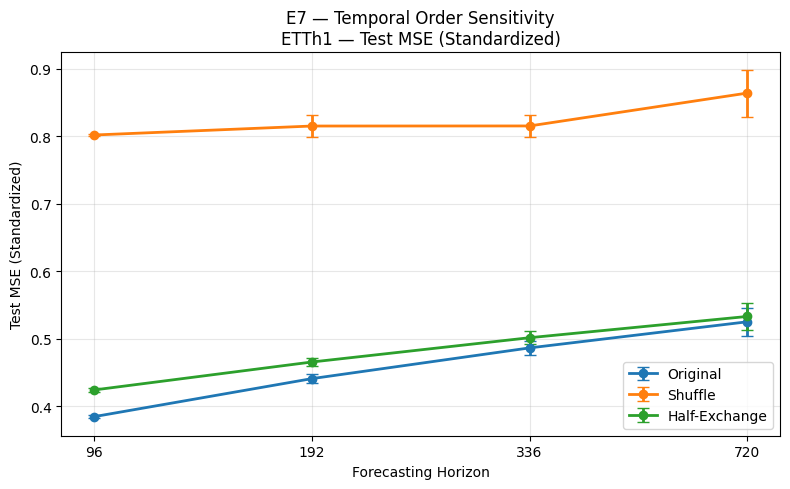

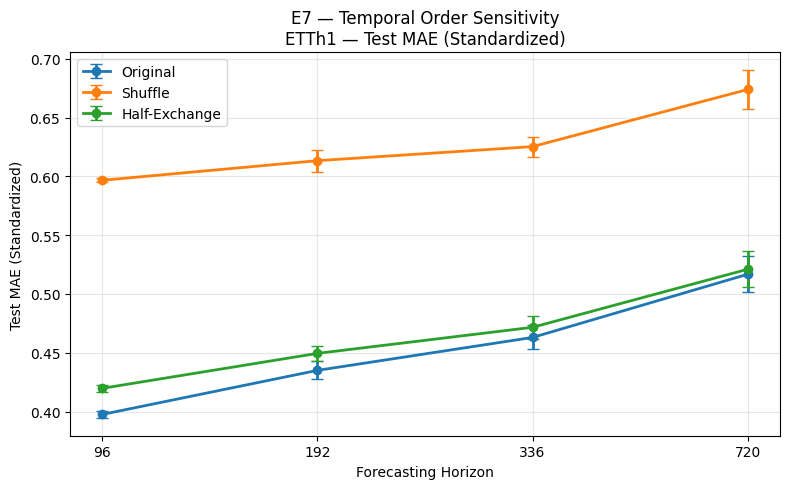

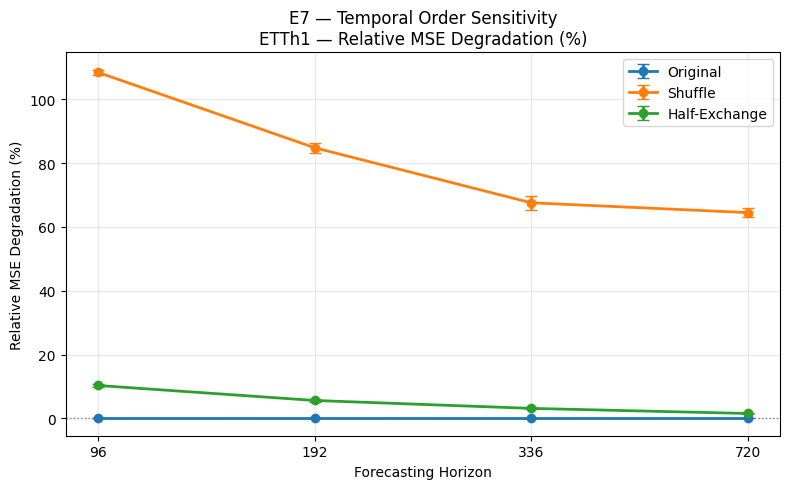

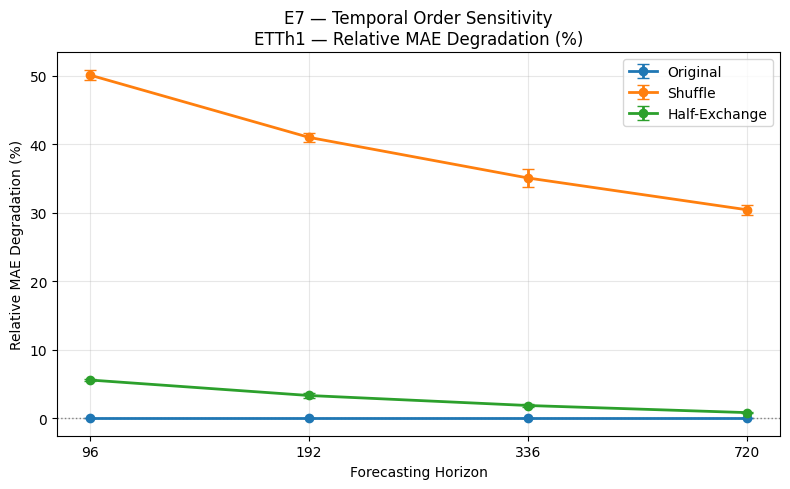


=== TEMPORAL ORDER VISUALIZATION ===
Saved: etth1_temporal_mse.png
Saved: etth1_temporal_mae.png
Saved: etth1_temporal_mse_degradation.png
Saved: etth1_temporal_mae_degradation.png

Evaluation rows: 60
Summary rows: 12
Total figures: 4
Output directory: c:\Users\Win 11 New\Desktop\pa gk\experiments\08_external_paper\results\temporal_order_test\figures

TEMPORAL ORDER VISUALIZATION PASSED!


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Load evaluation results
metrics_df = pd.read_csv(
    RESULTS_DIR / "temporal_order_metrics.csv"
)

summary_df = pd.read_csv(
    RESULTS_DIR / "temporal_order_summary.csv"
)

FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# 2. Verify results
assert len(metrics_df) == 60
assert len(summary_df) == 12

TRANSFORM_ORDER = [
    "Original",
    "Shuffle",
    "Half-Exchange"
]

assert set(summary_df["Transformation"]) == set(
    TRANSFORM_ORDER
)

for horizon in PRED_LENGTHS:
    for transformation in TRANSFORM_ORDER:

        subset = metrics_df[
            (metrics_df["Horizon"] == horizon)
            & (
                metrics_df["Transformation"]
                == transformation
            )
        ]

        assert len(subset) == 5
        assert set(subset["Seed"]) == set(EVAL_SEEDS)

# 3. Plot configuration
METRIC_CONFIGS = {
    "MSE": {
        "ylabel": "Test MSE (Standardized)",
        "filename": "etth1_temporal_mse.png"
    },
    "MAE": {
        "ylabel": "Test MAE (Standardized)",
        "filename": "etth1_temporal_mae.png"
    },
    "MSE_Degradation": {
        "ylabel": "Relative MSE Degradation (%)",
        "filename": "etth1_temporal_mse_degradation.png"
    },
    "MAE_Degradation": {
        "ylabel": "Relative MAE Degradation (%)",
        "filename": "etth1_temporal_mae_degradation.png"
    }
}

SAVED_FIGURES = []

# 4. Plot each metric
for metric, config in METRIC_CONFIGS.items():

    fig, ax = plt.subplots(figsize=(8, 5))

    x_positions = np.arange(len(PRED_LENGTHS))

    for transformation in TRANSFORM_ORDER:

        subset = (
            summary_df[
                summary_df["Transformation"]
                == transformation
            ]
            .set_index("Horizon")
            .reindex(PRED_LENGTHS)
        )

        assert subset[f"{metric}_Mean"].notna().all()
        assert subset[f"{metric}_Std"].notna().all()

        mean_values = subset[
            f"{metric}_Mean"
        ].to_numpy(dtype=float)

        std_values = subset[
            f"{metric}_Std"
        ].to_numpy(dtype=float)

        ax.errorbar(
            x_positions,
            mean_values,
            yerr=std_values,
            marker="o",
            linewidth=2,
            markersize=6,
            capsize=4,
            label=transformation
        )

    # Zero reference for degradation
    if "Degradation" in metric:
        ax.axhline(
            y=0,
            color="gray",
            linestyle=":",
            linewidth=1
        )

    ax.set_title(
        f"E7 — Temporal Order Sensitivity\n"
        f"ETTh1 — {config['ylabel']}"
    )

    ax.set_xlabel("Forecasting Horizon")
    ax.set_ylabel(config["ylabel"])

    ax.set_xticks(
        x_positions,
        [str(h) for h in PRED_LENGTHS]
    )

    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()

    output_path = FIG_DIR / config["filename"]

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    SAVED_FIGURES.append(output_path)

    plt.show()
    plt.close(fig)


# 5. Final verification
assert len(SAVED_FIGURES) == 4
assert all(p.is_file() for p in SAVED_FIGURES)

print("\n=== TEMPORAL ORDER VISUALIZATION ===")

for path in SAVED_FIGURES:
    print("Saved:", path.name)

print("\nEvaluation rows:", len(metrics_df))
print("Summary rows:", len(summary_df))
print("Total figures:", len(SAVED_FIGURES))
print("Output directory:", FIG_DIR)

print("\nTEMPORAL ORDER VISUALIZATION PASSED!")
